In [1]:
%pip install pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import warnings
import logging
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("All libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Scikit-learn version: 1.9.0


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

Current working directory:
C:\Users\pghat\Bank_Loan_Approval_Prediction

Files available in this folder:
['.ipynb_checkpoints', 'Bank_Loan_Approval_Prediction.ipynb']


In [4]:
import pandas as pd

DATA_PATH = r'C:\Users\pghat\Downloads\application_train.csv'

data = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully!")

print("Dataset shape:", data.shape)

display(data.head())

Dataset loaded successfully!
Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print("Dataset Information:")

data.info()

print("\nDataset Description:")

display(data.describe())

print("\nMissing Values:")

missing_values = data.isnull().sum()

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .head(20)
)

print("\nTarget Distribution:")

display(data["TARGET"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB

Dataset Description:


,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000



Missing Values:


COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64


Target Distribution:


TARGET
0    282686
1     24825
Name: count, dtype: int64

In [6]:
TARGET_COLUMN = "TARGET"

if TARGET_COLUMN not in data.columns:
    raise ValueError(
        "TARGET column not found. Please upload application_train.csv."
    )

data = data.dropna(subset=[TARGET_COLUMN]).copy()

data[TARGET_COLUMN] = pd.to_numeric(
    data[TARGET_COLUMN],
    errors="coerce"
)

data = data.dropna(subset=[TARGET_COLUMN]).copy()

data[TARGET_COLUMN] = data[TARGET_COLUMN].astype(int)

if set(data[TARGET_COLUMN].unique()) != {0, 1}:
    raise ValueError(
        "TARGET must contain both classes: 0 and 1."
    )

print("Dataset validation completed successfully.")

print("Final dataset shape:", data.shape)

Dataset validation completed successfully.
Final dataset shape: (307511, 122)


In [7]:
X = data.drop(columns=["TARGET"]).copy()

y = data["TARGET"].copy()

# Remove applicant identification column.
if "SK_ID_CURR" in X.columns:
    X = X.drop(columns=["SK_ID_CURR"])

# Replace infinite values with missing values.
numeric_columns = X.select_dtypes(include=["number"]).columns

X[numeric_columns] = X[numeric_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove completely empty columns.
empty_columns = X.columns[X.isna().all()].tolist()

if empty_columns:
    X = X.drop(columns=empty_columns)

print("Features and target separated successfully.")

print("Feature shape:", X.shape)

print("Target shape:", y.shape)

print("\nTarget classes:")

print(y.value_counts())

Features and target separated successfully.
Feature shape: (307511, 120)
Target shape: (307511,)

Target classes:
TARGET
0    282686
1     24825
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Use a stratified training sample for faster execution.
MAX_TRAIN_ROWS = 10000

if len(X_train) > MAX_TRAIN_ROWS:

    X_train, _, y_train, _ = train_test_split(
        X_train,
        y_train,
        train_size=MAX_TRAIN_ROWS,
        random_state=42,
        stratify=y_train
    )

print("Training and testing split completed.")

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

print("\nTraining target distribution:")

print(y_train.value_counts(normalize=True))

Training and testing split completed.
Training data: (10000, 120)
Testing data: (61503, 120)

Training target distribution:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


In [9]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

print("Numerical features:", len(numeric_features))

print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")

print(numeric_features)

print("\nCategorical columns:")

print(categorical_features)

Numerical features: 104
Categorical features: 16

Numerical columns:
['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA

In [10]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)

print("Numerical preprocessing pipeline created successfully.")

Numerical preprocessing pipeline created successfully.


In [11]:
try:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        max_categories=20,
        sparse_output=False
    )

except TypeError:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        max_categories=20,
        sparse=False
    )


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",
            encoder
        )
    ]
)

print("Categorical preprocessing pipeline created successfully.")

Categorical preprocessing pipeline created successfully.


In [12]:
transformers = []

if numeric_features:

    transformers.append(
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        )
    )

if categorical_features:

    transformers.append(
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    )


preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Combined preprocessing pipeline created successfully.")

Combined preprocessing pipeline created successfully.


In [13]:
classifier = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=10,
    subsample=0.8,
    random_state=42
)

print("Gradient Boosting Classifier initialized successfully.")

Gradient Boosting Classifier initialized successfully.


In [14]:
model_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),

        (
            "classifier",
            classifier
        )
    ]
)

print("Complete machine-learning pipeline created successfully.")

model_pipeline

Complete machine-learning pipeline created successfully.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

In [15]:
print("Model training started...")

model_pipeline.fit(
    X_train,
    y_train
)

print("Model training completed successfully!")

Model training started...
Model training completed successfully!


In [16]:
y_pred = model_pipeline.predict(X_test)

y_probability = model_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("First 10 predictions:")

print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")

print(y_probability[:10])

Predictions generated successfully.
First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted probabilities:
[0.06471162 0.04116346 0.21602744 0.06007447 0.10314873 0.1308297
 0.0265406  0.033839   0.28241955 0.07443618]


In [17]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Model Accuracy:", round(accuracy, 4))

print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.9193
Accuracy Percentage: 91.93 %


In [18]:
roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.7352


In [19]:
report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("Classification Report:")

print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.50      0.01      0.03      4965

    accuracy                           0.92     61503
   macro avg       0.71      0.51      0.49     61503
weighted avg       0.89      0.92      0.88     61503



In [20]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")

print(cm)

Confusion Matrix:
[[56471    67]
 [ 4898    67]]


<Figure size 800x600 with 0 Axes>

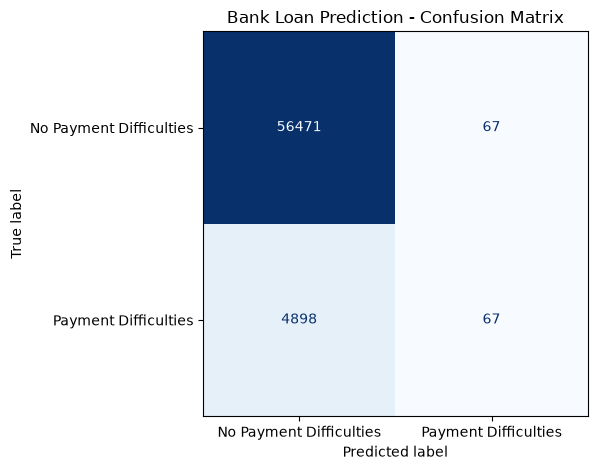

In [21]:
plt.figure(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[
        "No Payment Difficulties",
        "Payment Difficulties"
    ],
    cmap="Blues",
    colorbar=False
)

plt.title("Bank Loan Prediction - Confusion Matrix")

plt.tight_layout()

plt.show()

<Figure size 800x600 with 0 Axes>

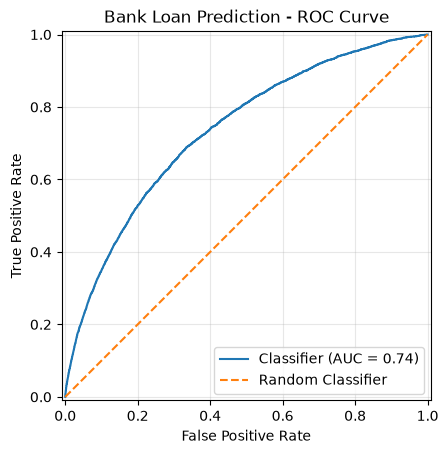

In [22]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Bank Loan Prediction - ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [23]:
output_dir = Path("artifacts")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory created successfully.")

print("Directory:", output_dir.resolve())

Output directory created successfully.
Directory: C:\Users\pghat\Bank_Loan_Approval_Prediction\artifacts


In [24]:
metrics = {
    "model": "GradientBoostingClassifier",

    "accuracy": float(accuracy),

    "roc_auc": float(roc_auc),

    "training_samples": int(len(X_train)),

    "testing_samples": int(len(X_test)),

    "confusion_matrix": cm.tolist(),

    "classification_report": classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
}

metrics_path = output_dir / "metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:

    json.dump(
        metrics,
        file,
        indent=4
    )

print("Evaluation metrics saved successfully.")

print("Saved file:", metrics_path)

Evaluation metrics saved successfully.
Saved file: artifacts\metrics.json


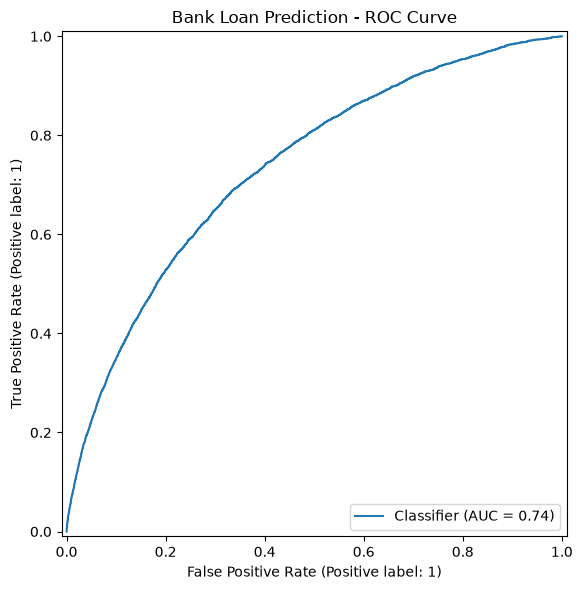

ROC curve saved successfully.
Saved file: artifacts\roc_curve.png


In [25]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_probability,
    ax=ax
)

ax.set_title("Bank Loan Prediction - ROC Curve")

fig.tight_layout()

roc_path = output_dir / "roc_curve.png"

fig.savefig(
    roc_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("ROC curve saved successfully.")

print("Saved file:", roc_path)

In [26]:
model_path = output_dir / "bank_loan_pipeline.joblib"

joblib.dump(
    model_pipeline,
    model_path,
    compress=3
)

print("Model exported successfully!")

print("Model location:", model_path.resolve())

Model exported successfully!
Model location: C:\Users\pghat\Bank_Loan_Approval_Prediction\artifacts\bank_loan_pipeline.joblib


In [27]:
metadata = {

    "project_name": "Bank Loan Approval Prediction",

    "algorithm": "GradientBoostingClassifier",

    "target_column": "TARGET",

    "random_state": 42,

    "feature_columns": X.columns.tolist(),

    "numeric_features": numeric_features,

    "categorical_features": categorical_features,

    "scikit_learn_version": sklearn.__version__,

    "model_file": "bank_loan_pipeline.joblib"

}

metadata_path = output_dir / "metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

print("Model metadata saved successfully.")

Model metadata saved successfully.


In [28]:
loaded_model = joblib.load(
    model_path
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [29]:
reloaded_predictions = loaded_model.predict(
    X_test
)

predictions_match = np.array_equal(
    y_pred,
    reloaded_predictions
)

print("Original and saved model predictions match:")

print(predictions_match)

if not predictions_match:

    raise RuntimeError(
        "Model verification failed!"
    )

print("Model verification completed successfully!")

Original and saved model predictions match:
True
Model verification completed successfully!


In [30]:
sample_applicant = X_test.iloc[[0]]

prediction = loaded_model.predict(
    sample_applicant
)[0]

probability = loaded_model.predict_proba(
    sample_applicant
)[0, 1]

print("Sample Applicant Prediction")

print("---------------------------")

print("Predicted Class:", prediction)

print(
    "Payment Difficulties Probability:",
    round(probability * 100, 2),
    "%"
)

if prediction == 1:

    print("Result: Payment Difficulties Risk")

else:

    print("Result: No Recorded Payment Difficulties Risk")

Sample Applicant Prediction
---------------------------
Predicted Class: 0
Payment Difficulties Probability: 6.47 %
Result: No Recorded Payment Difficulties Risk


In [31]:
print("FINAL PROJECT OUTPUT FILES")

print("--------------------------")

for file in sorted(output_dir.iterdir()):

    if file.is_file():

        print(
            file.name,
            "-",
            round(file.stat().st_size / 1024, 2),
            "KB"
        )

print("\nProject completed successfully!")

FINAL PROJECT OUTPUT FILES
--------------------------
bank_loan_pipeline.joblib - 53.07 KB
metadata.json - 7.42 KB
metrics.json - 1.17 KB
roc_curve.png - 51.47 KB

Project completed successfully!
